# Machine Learning Case Studies: CS2 and CS5

**Name:** T. Haresh  |  **Roll No:** 160124733174  |  **Section:** CSE-3  |  **Year:** III
**Faculty:** S. Durga Devi

This notebook has two case studies:

* **Part A (CS2):** Customer clustering for East-West Airlines (K-Means, Hierarchical, DBSCAN)
* **Part B (CS5):** Wine quality assessment using regression

In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style('whitegrid')
os.makedirs('figures', exist_ok=True)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# PART A: CS2 - Clustering Analysis (East-West Airlines)

## A1. Load the data

The dataset has details of 3,999 frequent flyer members: their miles balance, credit card miles, bonus miles, flight activity and how long they have been enrolled.

In [2]:
air = pd.read_excel('data/EastWestAirlines.xlsx', sheet_name='data')
print('Shape:', air.shape)
air.head()

Shape: (3999, 12)


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [3]:
air.info()

<class 'pandas.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


## A2. Data preprocessing

**Step 1: Missing values and duplicates.** The `ID#` column is only an identifier, so it is dropped.

In [4]:
print('Missing values:', air.isna().sum().sum())
print('Duplicate rows:', air.duplicated().sum())
data = air.drop(columns='ID#')
data.describe().T.round(2)

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Balance,3999.0,73601.33,100775.66,0.0,18527.5,43097.0,92404.0,1704838.0
Qual_miles,3999.0,144.11,773.66,0.0,0.0,0.0,0.0,11148.0
cc1_miles,3999.0,2.06,1.38,1.0,1.0,1.0,3.0,5.0
cc2_miles,3999.0,1.01,0.15,1.0,1.0,1.0,1.0,3.0
cc3_miles,3999.0,1.01,0.20,1.0,1.0,1.0,1.0,5.0
Bonus_miles,3999.0,17144.85,24150.97,0.0,1250.0,7171.0,23800.5,263685.0
Bonus_trans,3999.0,11.60,9.60,0.0,3.0,12.0,17.0,86.0
Flight_miles_12mo,3999.0,460.06,1400.21,0.0,0.0,0.0,311.0,30817.0
Flight_trans_12,3999.0,1.37,3.79,0.0,0.0,0.0,1.0,53.0
Days_since_enroll,3999.0,4118.56,2065.13,2.0,2330.0,4096.0,5790.5,8296.0


**Step 2: Outliers.** Miles and transaction columns are heavily skewed, so a few members have very large values. We remove a member only if a value is more than 5 standard deviations from the mean in one of the six main numeric columns. The limit of 5 removes only extreme cases and keeps the normal customers.

Rows before: 3999 | rows removed: 125 | rows after: 3874


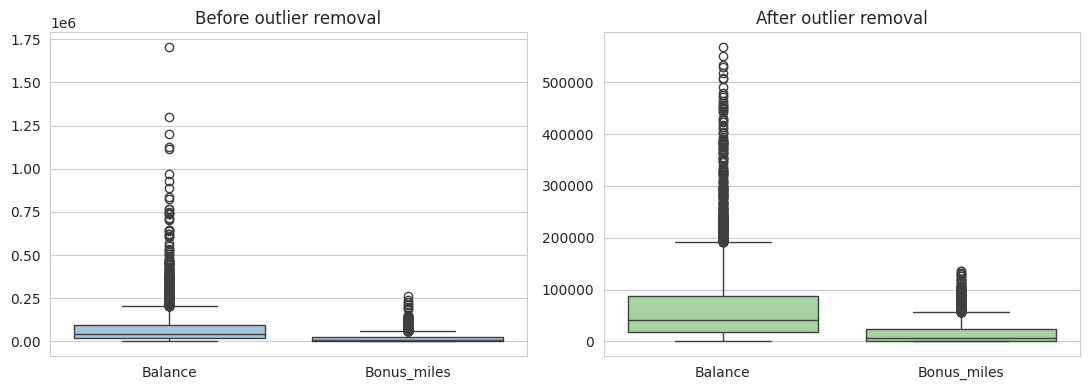

In [5]:
num_cols = ['Balance', 'Qual_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12']
z = (data[num_cols] - data[num_cols].mean()) / data[num_cols].std()
keep = (z.abs() <= 5).all(axis=1)
print('Rows before:', len(data), '| rows removed:', (~keep).sum(), '| rows after:', keep.sum())
clean = data[keep].reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=data[['Balance', 'Bonus_miles']], ax=axes[0], color='#9ecae1')
axes[0].set_title('Before outlier removal')
sns.boxplot(data=clean[['Balance', 'Bonus_miles']], ax=axes[1], color='#a1d99b')
axes[1].set_title('After outlier removal')
plt.tight_layout(); plt.savefig('figures/a_outliers.png', dpi=150); plt.show()

**Step 3: Scaling.** Features have very different ranges (Balance is in lakhs, `Award?` is 0 or 1). Distance-based algorithms need equal scales, so we use `StandardScaler`.

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(clean)
print('Scaled data shape:', X.shape)

Scaled data shape: (3874, 11)


## A3. Exploratory data analysis

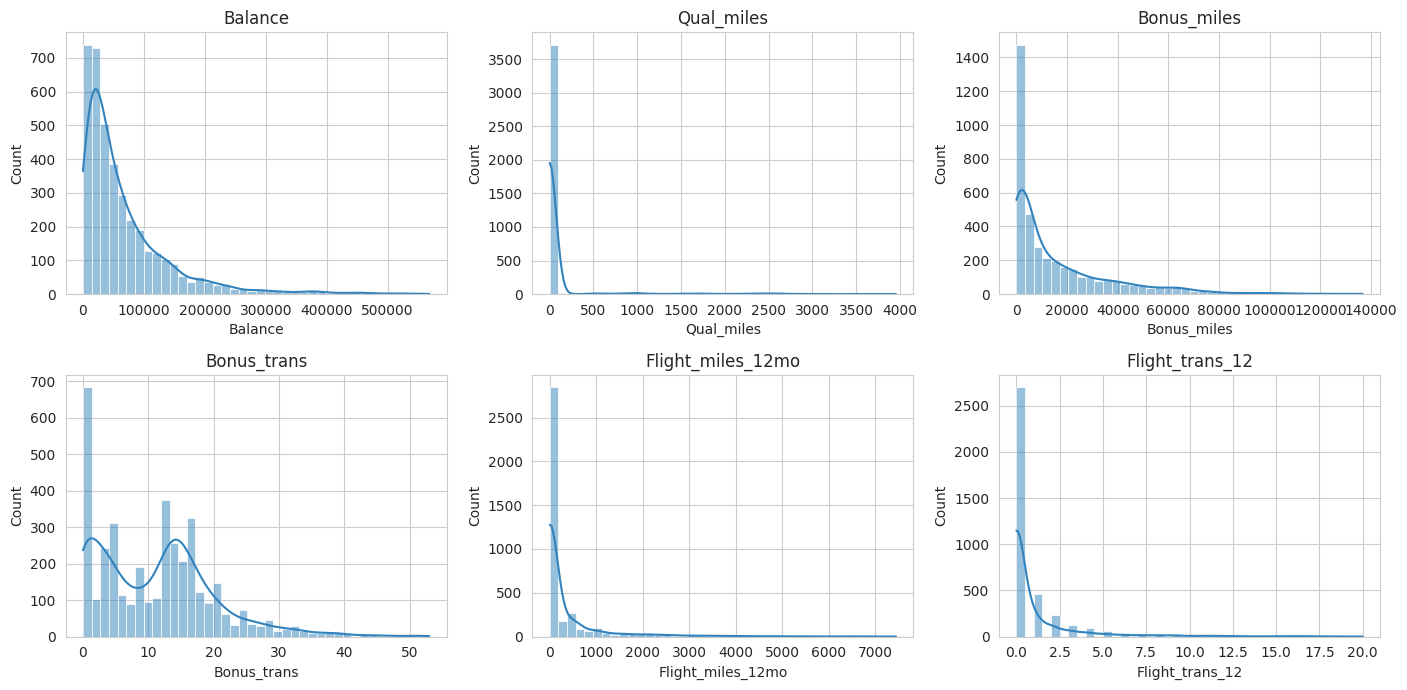

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(clean[c], bins=40, kde=True, ax=ax, color='#3182bd')
    ax.set_title(c)
plt.tight_layout(); plt.savefig('figures/a_hist.png', dpi=150); plt.show()

**Observation:** Balance, Bonus_miles, Bonus_trans and the flight columns are right-skewed. Most members have low values and a smaller group has very high values. Most members have zero qualifying miles and zero flights in the past year.

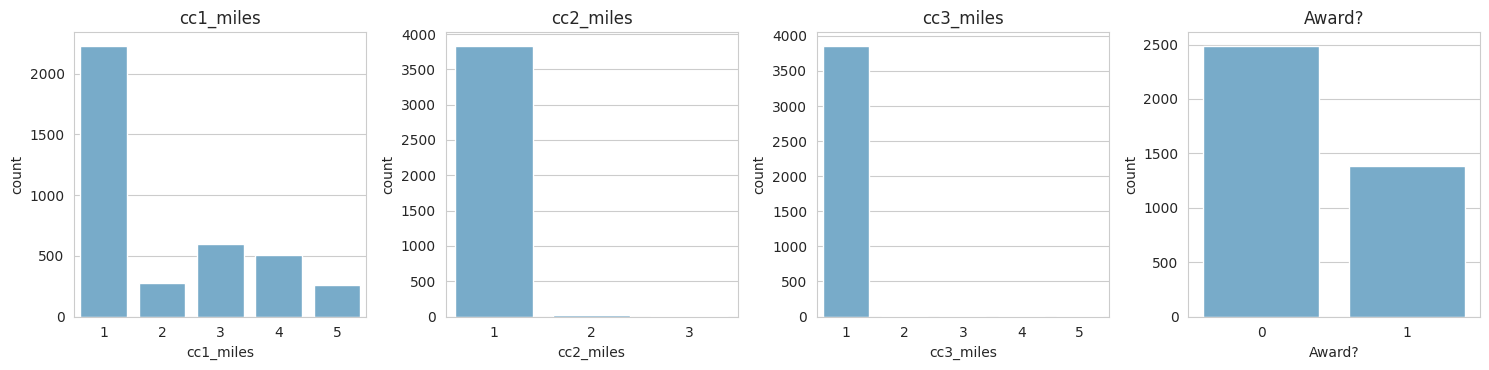

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, c in zip(axes, ['cc1_miles', 'cc2_miles', 'cc3_miles', 'Award?']):
    sns.countplot(x=clean[c], ax=ax, color='#6baed6')
    ax.set_title(c)
plt.tight_layout(); plt.savefig('figures/a_counts.png', dpi=150); plt.show()

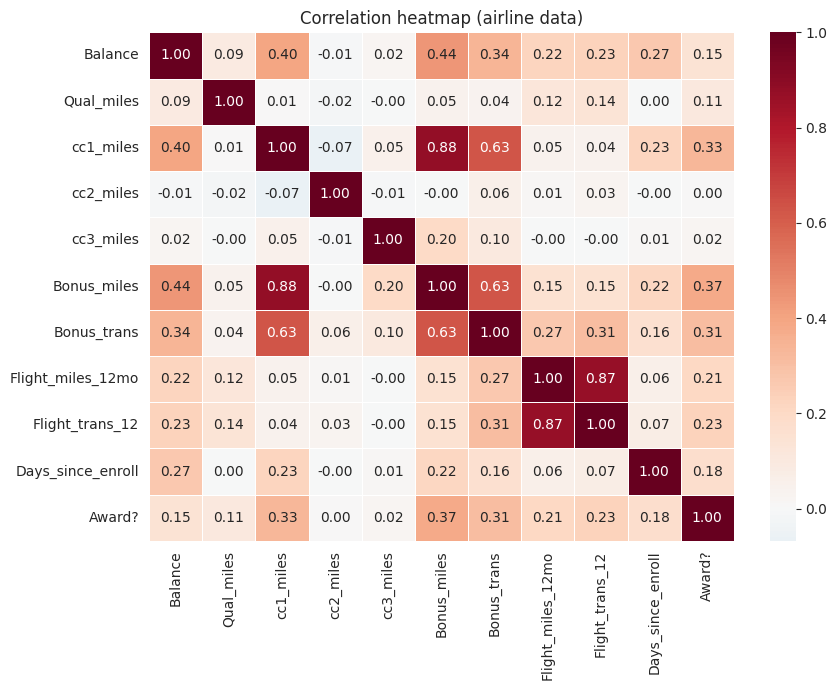

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(clean.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=.5)
plt.title('Correlation heatmap (airline data)')
plt.tight_layout(); plt.savefig('figures/a_heatmap.png', dpi=150); plt.show()

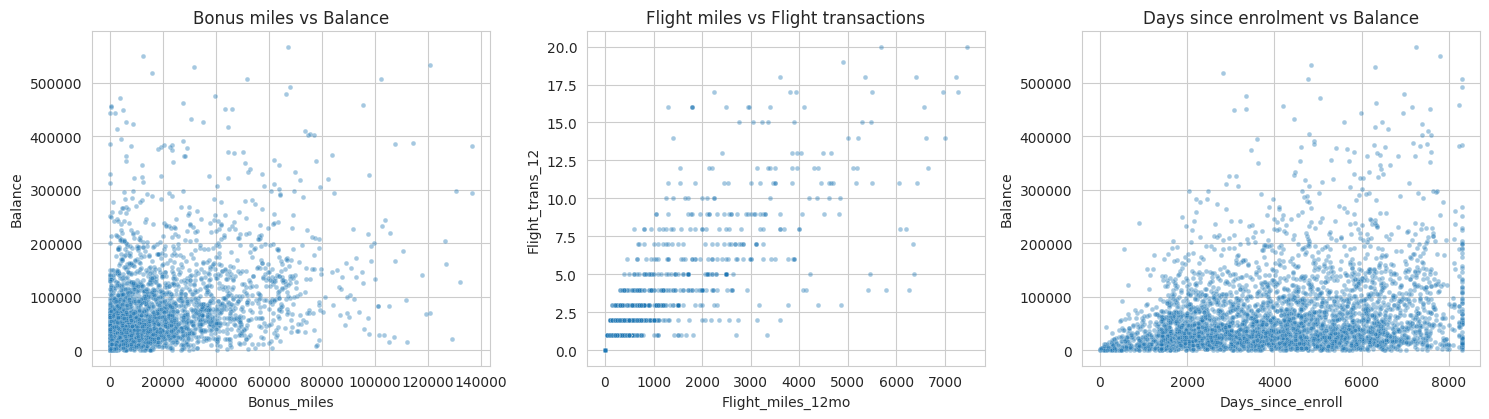

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
sns.scatterplot(data=clean, x='Bonus_miles', y='Balance', alpha=.4, s=12, ax=axes[0])
sns.scatterplot(data=clean, x='Flight_miles_12mo', y='Flight_trans_12', alpha=.4, s=12, ax=axes[1])
sns.scatterplot(data=clean, x='Days_since_enroll', y='Balance', alpha=.4, s=12, ax=axes[2])
axes[0].set_title('Bonus miles vs Balance'); axes[1].set_title('Flight miles vs Flight transactions'); axes[2].set_title('Days since enrolment vs Balance')
plt.tight_layout(); plt.savefig('figures/a_scatter.png', dpi=150); plt.show()

**Observations from EDA**

* `Bonus_miles` and `Bonus_trans` are strongly related, and `Balance` is also related to `Bonus_miles`.
* `Flight_miles_12mo` and `Flight_trans_12` move together, as expected.
* `cc1_miles` is related to `Balance` and `Bonus_miles`, so card users tend to earn more miles.
* Newer members (low `Days_since_enroll`) have smaller balances.

## A4. K-Means clustering

We try K from 2 to 10 and use the **Elbow curve** (inertia) and the **silhouette score** to choose K.

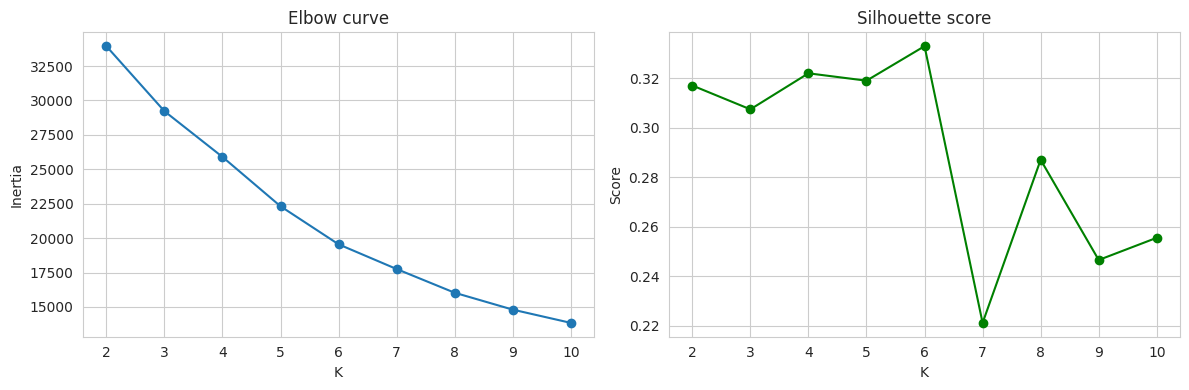

,K,Inertia,Silhouette
0,2,33945.2,0.3170
1,3,29221.3,0.3074
2,4,25898.5,0.3219
3,5,22313.4,0.3190
4,6,19550.4,0.3329
5,7,17755.3,0.2212
6,8,16032.6,0.2870
7,9,14806.8,0.2466
8,10,13844.4,0.2555


In [11]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertia, 'o-'); axes[0].set_title('Elbow curve'); axes[0].set_xlabel('K'); axes[0].set_ylabel('Inertia')
axes[1].plot(list(ks), sil, 'o-', color='green'); axes[1].set_title('Silhouette score'); axes[1].set_xlabel('K'); axes[1].set_ylabel('Score')
plt.tight_layout(); plt.savefig('figures/a_elbow.png', dpi=150); plt.show()
pd.DataFrame({'K': list(ks), 'Inertia': np.round(inertia, 1), 'Silhouette': np.round(sil, 4)})

The elbow becomes gentle around **K = 4**, and the silhouette score at K = 4 (about 0.32) is among the best values. K = 6 scores slightly higher, but it splits the data into small groups that are hard to explain. We choose **K = 4**.

In [12]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
clean['KMeans'] = km.labels_
sil_km = silhouette_score(X, km.labels_)
print('K-Means silhouette score:', round(sil_km, 4))
print(clean['KMeans'].value_counts().sort_index())

K-Means silhouette score: 0.3219
KMeans
0    2391
1    1196
2     247
3      40
Name: count, dtype: int64


In [13]:
profile_cols = num_cols + ['cc1_miles', 'cc2_miles', 'cc3_miles', 'Days_since_enroll', 'Award?']
clean.groupby('KMeans')[profile_cols].mean().round(1)

,Balance,Qual_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,cc1_miles,cc2_miles,cc3_miles,Days_since_enroll,Award?
KMeans,,,,,,,,,,,
0,41121.4,52.8,4331.7,6.6,122.5,0.4,1.2,1.0,1.0,3695.9,0.2
1,107061.1,68.3,38066.5,18.3,213.3,0.7,3.7,1.0,1.0,4835.7,0.6
2,121145.4,281.8,23611.5,19.8,3086.8,8.7,2.1,1.0,1.0,4481.2,0.7
3,50038.8,0.0,14555.7,15.8,288.8,1.1,1.1,2.4,1.0,3926.2,0.4


## A5. Hierarchical clustering

We compare four linkage methods: **ward, complete, average, single**. A dendrogram is drawn on a random sample of 500 members, because a dendrogram of all members is unreadable.

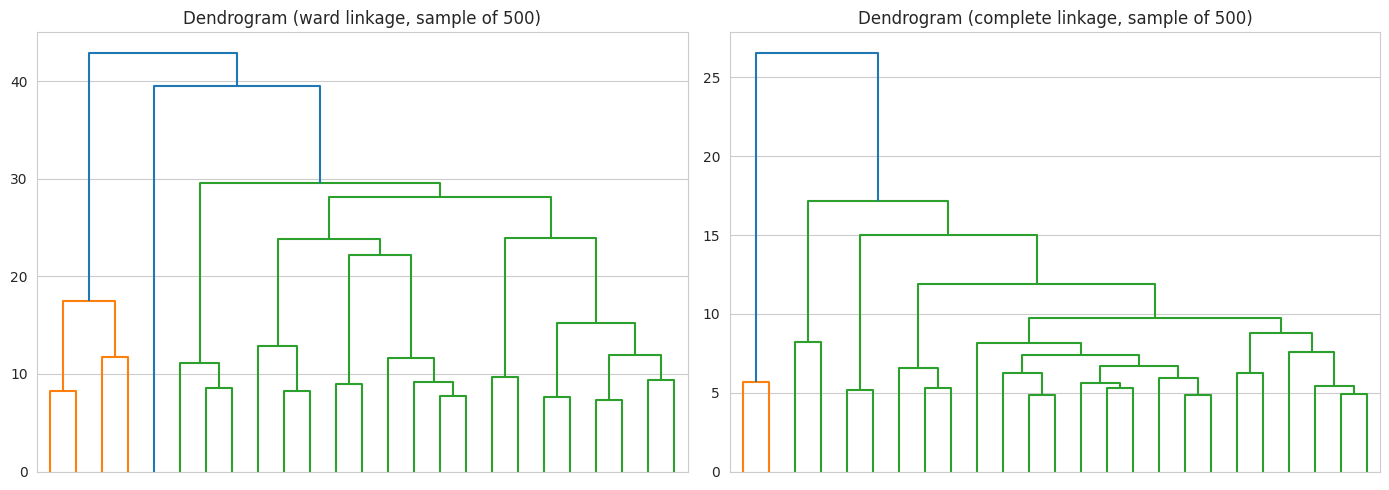

In [14]:
rng = np.random.RandomState(42)
idx = rng.choice(len(X), 500, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, m in zip(axes, ['ward', 'complete']):
    dendrogram(linkage(X[idx], method=m), truncate_mode='lastp', p=25, ax=ax, no_labels=True)
    ax.set_title(f'Dendrogram ({m} linkage, sample of 500)')
plt.tight_layout(); plt.savefig('figures/a_dendro.png', dpi=150); plt.show()

In [15]:
rows = []
for lk in ['ward', 'complete', 'average', 'single']:
    for k in [3, 4, 5]:
        lab = AgglomerativeClustering(n_clusters=k, linkage=lk).fit_predict(X)
        rows.append([lk, k, round(silhouette_score(X, lab), 4), sorted(np.bincount(lab), reverse=True)])
link_df = pd.DataFrame(rows, columns=['Linkage', 'Clusters', 'Silhouette', 'Cluster sizes'])
link_df

,Linkage,Clusters,Silhouette,Cluster sizes
0,ward,3,0.2761,"[2168, 1533, 173]"
1,ward,4,0.2793,"[2168, 1517, 173, 16]"
2,ward,5,0.2916,"[2128, 1517, 173, 40, 16]"
3,complete,3,0.6272,"[3825, 40, 9]"
4,complete,4,0.6204,"[3818, 40, 9, 7]"
5,complete,5,0.5398,"[3714, 104, 40, 9, 7]"
6,average,3,0.6313,"[3819, 42, 13]"
7,average,4,0.6196,"[3819, 40, 13, 2]"
8,average,5,0.5809,"[3795, 40, 24, 13, 2]"
9,single,3,0.5339,"[3832, 28, 14]"


Complete, average and single linkage get higher silhouette scores, but only because they put almost all members in one giant cluster and a few tiny clusters. That is not useful for customer segments. **Ward linkage** gives balanced groups, so we use Ward with 4 clusters.

In [16]:
hc = AgglomerativeClustering(n_clusters=4, linkage='ward').fit(X)
clean['Hierarchical'] = hc.labels_
sil_hc = silhouette_score(X, hc.labels_)
print('Hierarchical (Ward, 4 clusters) silhouette score:', round(sil_hc, 4))
print(clean['Hierarchical'].value_counts().sort_index())
clean.groupby('Hierarchical')[profile_cols].mean().round(1)

Hierarchical (Ward, 4 clusters) silhouette score: 0.2793
Hierarchical
0    2168
1    1517
2     173
3      16
Name: count, dtype: int64


,Balance,Qual_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,cc1_miles,cc2_miles,cc3_miles,Days_since_enroll,Award?
Hierarchical,,,,,,,,,,,
0,38897.0,1.8,3687.9,6.0,130.5,0.5,1.1,1.0,1.0,3743.9,0.2
1,99500.5,148.9,32402.2,17.5,286.6,0.8,3.4,1.0,1.0,4584.5,0.5
2,124428.1,269.7,22299.9,18.7,3462.0,9.9,1.8,1.0,1.0,4281.3,0.7
3,93345.6,73.9,80729.9,25.5,340.6,1.1,3.3,1.0,3.6,4512.6,0.5


## A6. DBSCAN

DBSCAN needs `eps` (neighbourhood radius) and `min_samples`. The **k-distance plot** helps choose `eps`: we look for the point where the curve bends sharply upward.

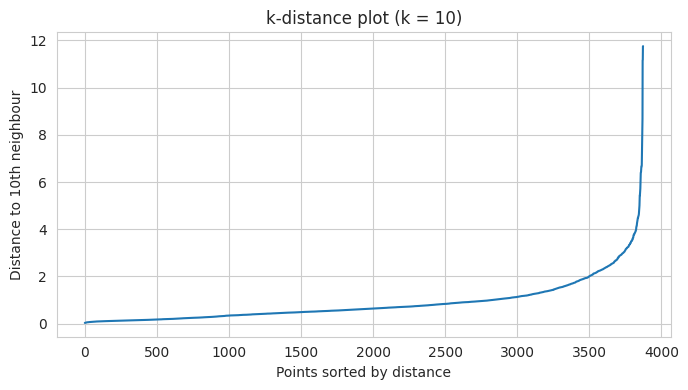

In [17]:
nn = NearestNeighbors(n_neighbors=10).fit(X)
dist, _ = nn.kneighbors(X)
plt.figure(figsize=(7, 4))
plt.plot(np.sort(dist[:, -1]))
plt.title('k-distance plot (k = 10)'); plt.xlabel('Points sorted by distance'); plt.ylabel('Distance to 10th neighbour')
plt.tight_layout(); plt.savefig('figures/a_kdist.png', dpi=150); plt.show()

In [18]:
rows = []
for eps in [0.8, 1.0, 1.2, 1.5, 2.0]:
    for ms in [5, 10, 20]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        s = silhouette_score(X[lab != -1], lab[lab != -1]) if n_cl > 1 else np.nan
        rows.append([eps, ms, n_cl, (lab == -1).sum(), round(s, 4)])
db_df = pd.DataFrame(rows, columns=['eps', 'min_samples', 'Clusters', 'Noise points', 'Silhouette (no noise)'])
db_df

,eps,min_samples,Clusters,Noise points,Silhouette (no noise)
0,0.8,5,8,871,0.2147
1,0.8,10,4,1074,0.2748
2,0.8,20,2,1308,0.3411
3,1.0,5,8,646,0.2606
4,1.0,10,2,767,0.3062
5,1.0,20,2,911,0.3237
6,1.2,5,5,477,0.2938
7,1.2,10,3,596,0.2975
8,1.2,20,2,680,0.3013
9,1.5,5,7,334,0.2128


Small `eps` marks too many members as noise, and large `eps` merges everything into one or two groups. We choose **eps = 1.2 and min_samples = 10**, which gives 3 clusters with a reasonable amount of noise. The silhouette score is calculated on clustered points only (noise excluded).

In [19]:
db = DBSCAN(eps=1.2, min_samples=10).fit(X)
clean['DBSCAN'] = db.labels_
mask = db.labels_ != -1
sil_db = silhouette_score(X[mask], db.labels_[mask])
print('DBSCAN clusters:', len(set(db.labels_)) - 1, '| noise points:', (~mask).sum())
print('DBSCAN silhouette score (excluding noise):', round(sil_db, 4))
print(clean['DBSCAN'].value_counts().sort_index())
clean.groupby('DBSCAN')[profile_cols].mean().round(1)

DBSCAN clusters: 3 | noise points: 596
DBSCAN silhouette score (excluding noise): 0.2975
DBSCAN
-1     596
 0    2259
 1    1009
 2      10
Name: count, dtype: int64


,Balance,Qual_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,cc1_miles,cc2_miles,cc3_miles,Days_since_enroll,Award?
DBSCAN,,,,,,,,,,,
-1,137447.1,465.8,32197.2,19.1,1553.0,4.5,2.6,1.1,1.1,4616.6,0.6
0,52253.9,0.0,8961.3,8.4,90.4,0.3,1.7,1.0,1.0,3798.7,0.0
1,57539.2,0.0,22578.0,12.8,190.3,0.6,2.6,1.0,1.0,4482.1,1.0
2,27372.7,0.0,8459.1,11.7,0.0,0.0,1.0,2.0,1.0,2919.1,0.0


## A7. Visualising the clusters (PCA)

The data has 11 features, so we use PCA to reduce it to 2 dimensions for plotting.

Variance explained by 2 components: [0.297 0.16 ] | total: 0.457


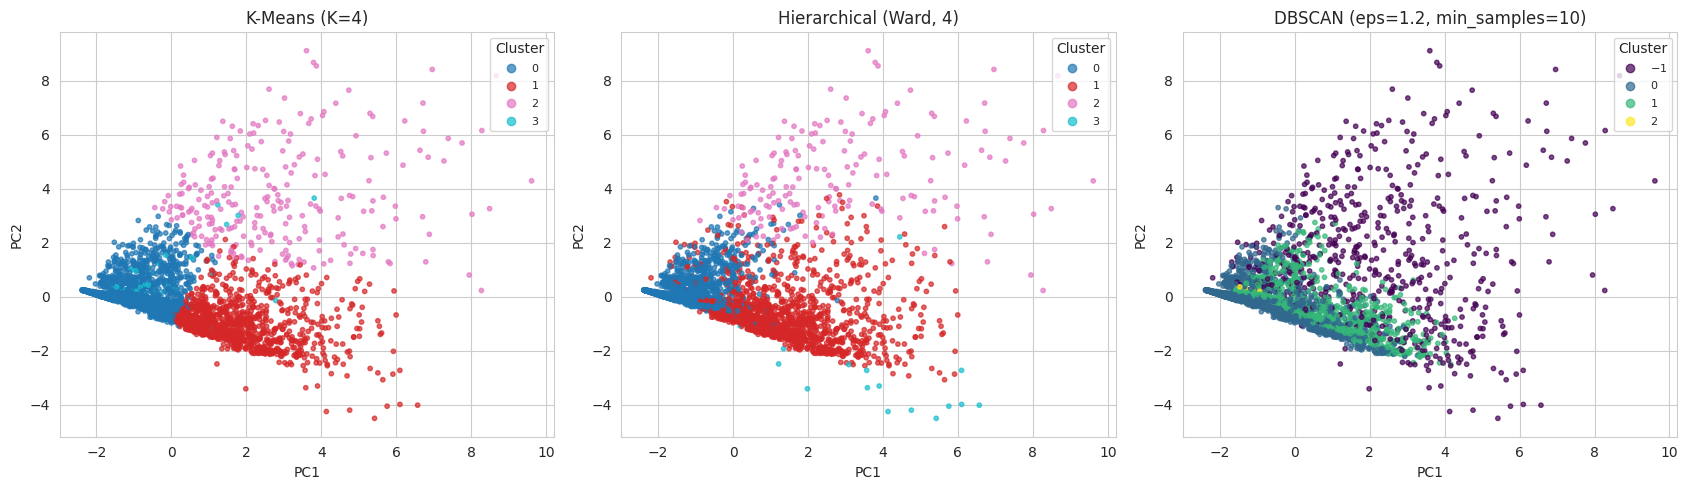

In [20]:
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
print('Variance explained by 2 components:', pca.explained_variance_ratio_.round(3), '| total:', pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col, title in zip(axes, ['KMeans', 'Hierarchical', 'DBSCAN'], ['K-Means (K=4)', 'Hierarchical (Ward, 4)', 'DBSCAN (eps=1.2, min_samples=10)']):
    sc = ax.scatter(P[:, 0], P[:, 1], c=clean[col], cmap='tab10' if col != 'DBSCAN' else 'viridis', s=10, alpha=.7)
    ax.set_title(title); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.legend(*sc.legend_elements(), title='Cluster', loc='upper right', fontsize=8)
plt.tight_layout(); plt.savefig('figures/a_clusters.png', dpi=150); plt.show()

In the DBSCAN plot, the cluster labelled **-1** is noise (outlying members).

## A8. Evaluation and comparison

In [21]:
summary = pd.DataFrame({
    'Algorithm': ['K-Means (K=4)', 'Hierarchical (Ward, 4)', 'DBSCAN (eps=1.2, min_samples=10)'],
    'Clusters': [4, 4, len(set(db.labels_)) - 1],
    'Silhouette score': [round(sil_km, 4), round(sil_hc, 4), round(sil_db, 4)]
})
summary

,Algorithm,Clusters,Silhouette score
0,K-Means (K=4),4,0.3219
1,"Hierarchical (Ward, 4)",4,0.2793
2,"DBSCAN (eps=1.2, min_samples=10)",3,0.2975


## A9. Cluster interpretation (insights)

Cluster means from the K-Means table above are used to name the segments. Exact numbers are in the report.

In [22]:
# Segment names are decided by looking at the K-Means profile table
km_prof = clean.groupby('KMeans')[profile_cols].mean().round(1)
km_prof['Members'] = clean['KMeans'].value_counts().sort_index()
km_prof

,Balance,Qual_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,cc1_miles,cc2_miles,cc3_miles,Days_since_enroll,Award?,Members
KMeans,,,,,,,,,,,,
0,41121.4,52.8,4331.7,6.6,122.5,0.4,1.2,1.0,1.0,3695.9,0.2,2391
1,107061.1,68.3,38066.5,18.3,213.3,0.7,3.7,1.0,1.0,4835.7,0.6,1196
2,121145.4,281.8,23611.5,19.8,3086.8,8.7,2.1,1.0,1.0,4481.2,0.7,247
3,50038.8,0.0,14555.7,15.8,288.8,1.1,1.1,2.4,1.0,3926.2,0.4,40


**Insights (K-Means segments)**

* **Cluster 0 - Casual members (2,391 members, about 62%):** Low balance (about 41,000), very few bonus miles and almost no credit card use. They joined more recently and only 20% have claimed an award.
* **Cluster 1 - Credit card loyalists (1,196 members, about 31%):** Highest credit card level (cc1 about 3.7), highest bonus miles (about 38,000) and a high balance. They have been members the longest and over half have claimed an award.
* **Cluster 2 - Frequent flyers (247 members, about 6%):** Very high flight miles (about 3,087) and about 9 flight transactions a year, with the highest balance. They are the only group with a large number of qualifying miles.
* **Cluster 3 - Rewards card users (40 members, about 1%):** A small group that mostly uses the Rewards credit card (cc2) and has no qualifying miles.

**Hierarchical:** Ward gives almost the same first three segments as K-Means. Its fourth cluster is 16 members with very high bonus miles (about 80,000) who use the Small Business card (cc3).

**DBSCAN:** It separates members mainly by award status. Cluster 0 has no award members, cluster 1 has only award members, and a tiny cluster 2 has 10 members. About 596 members (15%) are marked as noise: these are high-value, unusual customers with very high balances and flight activity.

**Comparison:** K-Means has the best silhouette score (0.32) and gives segments that are easy to explain, so it is the most suitable algorithm for this dataset. All scores are around 0.3, which means the clusters overlap to some extent, since customer behaviour changes gradually and not in sharp groups.

# PART B: CS5 - Wine Quality Assessment

## B1. Load the data

The two CSV files (red and white Vinho Verde wine) are combined into one dataset. Both files have the same 11 physicochemical attributes and the `quality` score.

In [23]:
red = pd.read_csv('data/winequality-red.csv', sep=';')
white = pd.read_csv('data/winequality-white.csv', sep=';')
print('Red:', red.shape, '| White:', white.shape)
wine = pd.concat([red, white], ignore_index=True)
print('Combined:', wine.shape)
print('Missing values:', wine.isna().sum().sum())
wine.head()

Red: (1599, 12) | White: (4898, 12)
Combined: (6497, 12)
Missing values: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [24]:
wine.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


## Task 1: Statistical analysis

**1a. Mean, median, mode, standard deviation and skewness**

In [25]:
three = ['alcohol', 'volatile acidity', 'residual sugar']
stat = pd.DataFrame({
    'Mean': wine[three].mean(),
    'Median': wine[three].median(),
    'Mode': [wine[c].mode()[0] for c in three],
    'Std Dev': wine[three].std(),
    'Skewness': wine[three].skew()
}).round(4)
stat

,Mean,Median,Mode,Std Dev,Skewness
alcohol,10.4918,10.30,9.50,1.1927,0.5657
volatile acidity,0.3397,0.29,0.28,0.1646,1.4951
residual sugar,5.4432,3.00,2.00,4.7578,1.4354


**1b. Relative variability (Coefficient of Variation = Std Dev / Mean x 100)**

In [26]:
cv = (wine[three].std() / wine[three].mean() * 100).round(2)
print(cv.to_string())
print('\nHighest relative variability:', cv.idxmax(), f'({cv.max()}%)')

alcohol             11.37
volatile acidity    48.47
residual sugar      87.41

Highest relative variability: residual sugar (87.41%)


**Interpretation:** Residual sugar has the highest coefficient of variation (87.4%), followed by volatile acidity (48.5%) and alcohol (11.4%). Standard deviation alone cannot be compared across attributes because their units differ, so CV is the right measure. Volatile acidity and residual sugar are also strongly right-skewed (skewness about 1.5 and 1.4), meaning most wines have low values and a few have very high values.

**1c. Pearson correlation between alcohol and quality**

In [27]:
r, p = stats.pearsonr(wine['alcohol'], wine['quality'])
print(f'Pearson r = {r:.4f}, p-value = {p:.3e}')

Pearson r = 0.4443, p-value = 1.498e-312


**Interpretation:** r = 0.44 is a **moderate positive** relationship. Wines with higher alcohol content tend to get higher quality scores. The p-value is almost zero, so this is not due to chance. However, r-squared is only about 0.20, so alcohol alone explains about 20% of the variation in quality.

## Task 2: Exploratory data analysis

**2a. Histogram of quality scores**

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Skewness of quality: 0.19


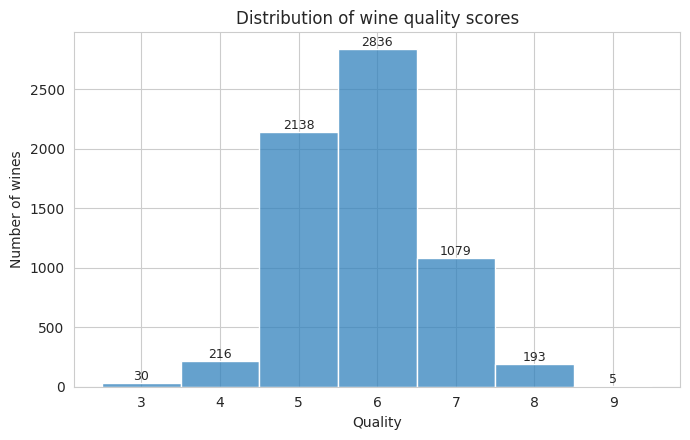

In [28]:
plt.figure(figsize=(7, 4.5))
ax = sns.histplot(wine['quality'], discrete=True, color='#3182bd')
for b in ax.patches:
    ax.annotate(int(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height()), ha='center', va='bottom', fontsize=9)
plt.title('Distribution of wine quality scores'); plt.xlabel('Quality'); plt.ylabel('Number of wines')
plt.tight_layout(); plt.savefig('figures/b_quality_hist.png', dpi=150); plt.show()
print(wine['quality'].value_counts().sort_index().to_string())
print('Skewness of quality:', round(wine['quality'].skew(), 3))

**Interpretation:** Quality scores range from 3 to 9, but about 77% of wines are rated 5 or 6. The shape is close to a bell curve with a very slight right skew (0.19). Very poor (3) and excellent (9) wines are rare (30 and 5 wines), so the model has very little data about the extremes.

**2b. Box plot of alcohol by quality**

         count  median   mean
quality                      
3           30   10.15  10.22
4          216   10.00  10.18
5         2138    9.60   9.84
6         2836   10.50  10.59
7         1079   11.40  11.39
8          193   12.00  11.68
9            5   12.50  12.18


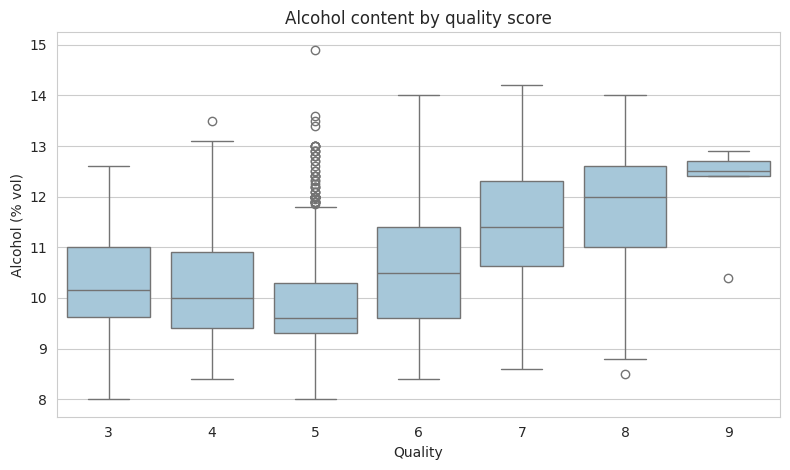

In [29]:
plt.figure(figsize=(8, 4.8))
sns.boxplot(data=wine, x='quality', y='alcohol', color='#9ecae1')
plt.title('Alcohol content by quality score'); plt.xlabel('Quality'); plt.ylabel('Alcohol (% vol)')
plt.tight_layout(); plt.savefig('figures/b_box_alcohol.png', dpi=150); plt.show()
print(wine.groupby('quality')['alcohol'].agg(['count', 'median', 'mean']).round(2))

**Interpretation:** Median alcohol is lowest for quality 5 (about 9.6%) and rises steadily to about 11.4% at quality 7 and 12% at quality 8. Higher quality wines clearly have more alcohol. Qualities 3 and 4 do not follow the pattern strongly because they have few wines. Several dots outside the whiskers (potential outliers) appear in most groups, mainly at the high alcohol end for quality 5 and 6.

**2c. Correlation heatmap**

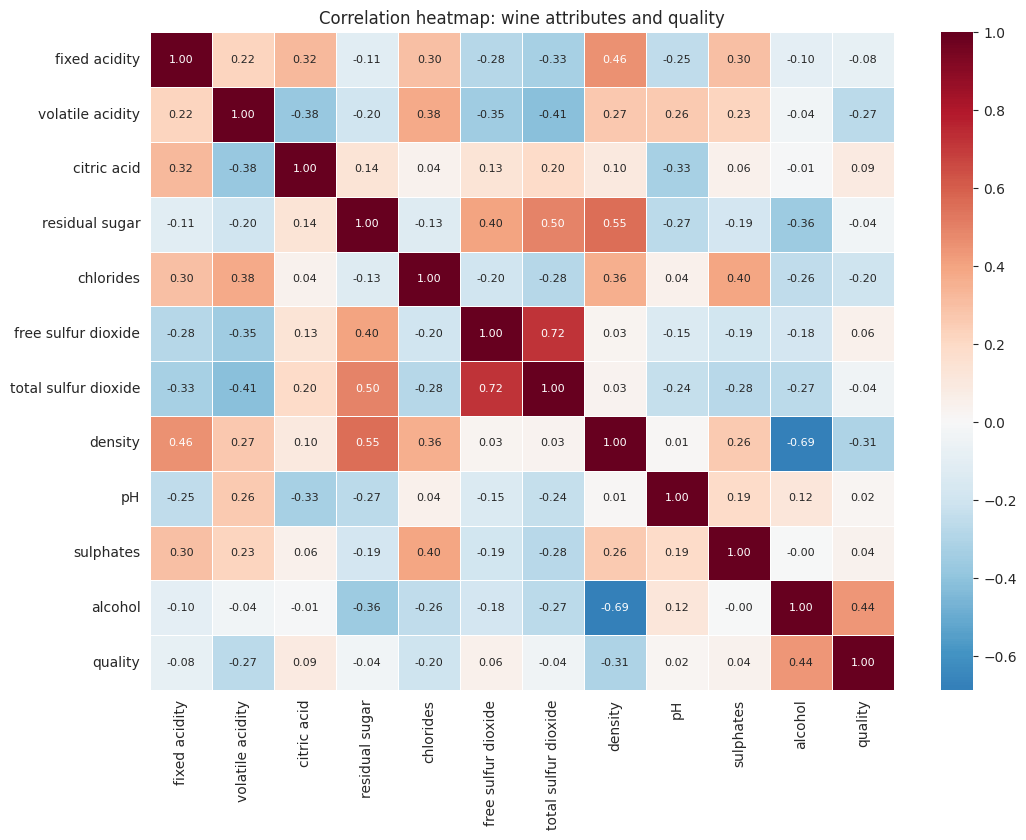

In [30]:
corr = wine.corr()
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=.5, annot_kws={'size': 8})
plt.title('Correlation heatmap: wine attributes and quality')
plt.tight_layout(); plt.savefig('figures/b_heatmap.png', dpi=150); plt.show()

**Interpretation:** Alcohol shows the strongest link with quality. Density is strongly negatively related to alcohol and strongly positively related to residual sugar, and free and total sulfur dioxide are also related to each other. These links between predictors matter for the regression in Task 3.

**2d. Two attributes most strongly associated with quality**

In [31]:
qc = corr['quality'].drop('quality')
order = qc.abs().sort_values(ascending=False)
print(qc[order.index].round(4).to_string())
print('\nTop two:', list(order.index[:2]))

alcohol                 0.4443
density                -0.3059
volatile acidity       -0.2657
chlorides              -0.2007
citric acid             0.0855
fixed acidity          -0.0767
free sulfur dioxide     0.0555
total sulfur dioxide   -0.0414
sulphates               0.0385
residual sugar         -0.0370
pH                      0.0195

Top two: ['alcohol', 'density']


**Interpretation:** The two attributes with the highest absolute correlation are **alcohol (r = +0.44, positive)** and **density (r = -0.31, negative)**. More alcohol goes with better quality, and denser wines tend to have lower quality. Density is largely a result of alcohol and sugar content (alcohol makes wine lighter), so the two findings are connected.

## Task 3: Predictive modelling

**3a and 3b. Multiple linear regression with an 80/20 split (random_state = 42)**

In [32]:
features = [c for c in wine.columns if c != 'quality']
Xw, yw = wine[features], wine['quality']
X_train, X_test, y_train, y_test = train_test_split(Xw, yw, test_size=0.2, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

lr = LinearRegression().fit(X_train, y_train)
y_pred = lr.predict(X_test)

Train: (5197, 11) | Test: (1300, 11)


**3c. Test-set metrics**

In [33]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
metrics = pd.DataFrame({'Metric': ['MAE', 'MSE', 'RMSE', 'R-squared'], 'Value': [mae, mse, rmse, r2]}).round(4)
metrics

,Metric,Value
0,MAE,0.5659
1,MSE,0.5467
2,RMSE,0.7394
3,R-squared,0.2598


**3d. Standardized coefficients and multicollinearity**

In [34]:
# Standardised coefficients: fit the same model on standardised X and y (training data)
sx, sy = StandardScaler(), StandardScaler()
Xs = sx.fit_transform(X_train)
ys = sy.fit_transform(y_train.values.reshape(-1, 1)).ravel()
std_model = LinearRegression().fit(Xs, ys)
coef = pd.DataFrame({'Feature': features, 'Std. coefficient': std_model.coef_, 'Raw coefficient': lr.coef_})
coef['Abs'] = coef['Std. coefficient'].abs()
coef = coef.sort_values('Abs', ascending=False).drop(columns='Abs').reset_index(drop=True)
coef.round(4)

,Feature,Std. coefficient,Raw coefficient
0,alcohol,0.3678,0.2707
1,residual sugar,0.2514,0.0459
2,volatile acidity,-0.2499,-1.3508
3,density,-0.2023,-58.9451
4,total sulfur dioxide,-0.1706,-0.0027
5,free sulfur dioxide,0.1398,0.0070
6,sulphates,0.1371,0.8084
7,fixed acidity,0.1161,0.0790
8,pH,0.0879,0.4828
9,citric acid,-0.0237,-0.1438


In [35]:
# Variance Inflation Factor (VIF): regress each feature on all the others
def vif_table(df):
    out = []
    for c in df.columns:
        others = df.drop(columns=c)
        r2_c = LinearRegression().fit(others, df[c]).score(others, df[c])
        out.append([c, 1 / (1 - r2_c)])
    return pd.DataFrame(out, columns=['Feature', 'VIF']).sort_values('VIF', ascending=False).reset_index(drop=True)

vif = vif_table(X_train)
vif.round(2)

,Feature,VIF
0,density,15.51
1,residual sugar,7.20
2,fixed acidity,4.74
3,alcohol,4.62
4,total sulfur dioxide,2.96
5,pH,2.47
6,free sulfur dioxide,2.16
7,volatile acidity,1.94
8,chlorides,1.65
9,citric acid,1.61


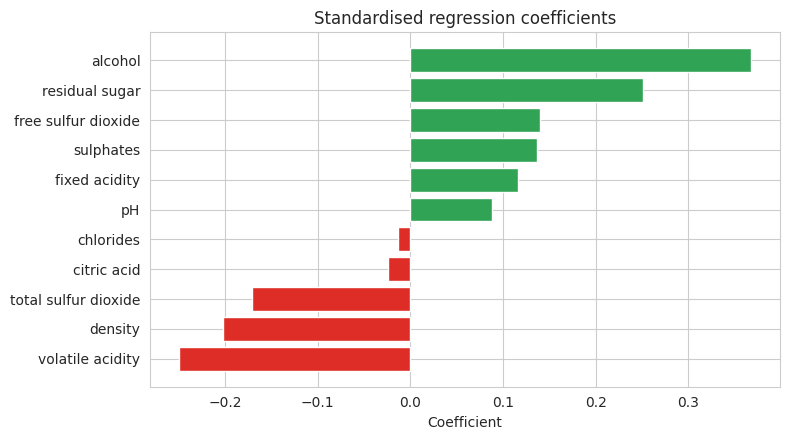

In [36]:
plt.figure(figsize=(8, 4.5))
cs = coef.sort_values('Std. coefficient')
plt.barh(cs['Feature'], cs['Std. coefficient'], color=['#de2d26' if v < 0 else '#31a354' for v in cs['Std. coefficient']])
plt.title('Standardised regression coefficients'); plt.xlabel('Coefficient')
plt.tight_layout(); plt.savefig('figures/b_coefs.png', dpi=150); plt.show()

In [37]:
# Check: how the model changes if the highly collinear 'density' is removed
feat2 = [f for f in features if f != 'density']
lr2 = LinearRegression().fit(X_train[feat2], y_train)
p2 = lr2.predict(X_test[feat2])
print('R2 with density   :', round(r2, 4), '| RMSE:', round(rmse, 4))
print('R2 without density:', round(r2_score(y_test, p2), 4), '| RMSE:', round(np.sqrt(mean_squared_error(y_test, p2)), 4))
s2 = StandardScaler().fit(X_train[feat2])
m2 = LinearRegression().fit(s2.transform(X_train[feat2]), ys)
print(pd.Series(m2.coef_, index=feat2).round(3).sort_values(key=abs, ascending=False).head(4).to_string())

R2 with density   : 0.2598 | RMSE: 0.7394
R2 without density: 0.2593 | RMSE: 0.7396
alcohol                 0.460
volatile acidity       -0.275
total sulfur dioxide   -0.155
free sulfur dioxide     0.140


**Interpretation of 3d**

* Most influential by standardized coefficient: **alcohol (+0.368)** and **residual sugar (+0.251)**. Volatile acidity (-0.250) is almost tied with residual sugar.
* **Multicollinearity:** Density has a VIF of 15.5 and residual sugar 7.2, both above the usual comfort level of 5. So the coefficients of these two cannot be trusted fully. A warning sign is that residual sugar has almost no correlation with quality (r = -0.04) but a positive coefficient in the model, which happens when density takes over part of its effect.
* After dropping density, R-squared stays at 0.259 (no loss), so density is redundant. Alcohol then becomes even stronger (0.46) and **volatile acidity (-0.28)** becomes the clear second predictor. So alcohol is a firm result, while the second place is less stable.

**3e. Actual vs predicted scores**

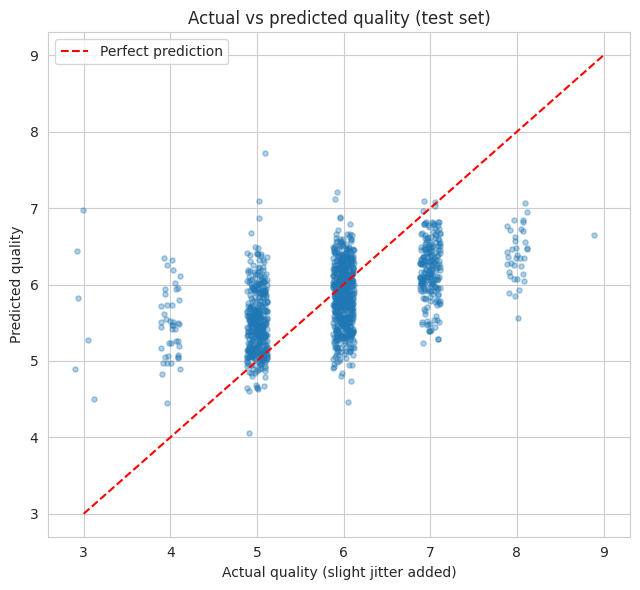

In [38]:
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test + np.random.RandomState(1).uniform(-.12, .12, len(y_test)), y_pred, alpha=.35, s=14)
plt.plot([3, 9], [3, 9], 'r--', label='Perfect prediction')
plt.xlabel('Actual quality (slight jitter added)'); plt.ylabel('Predicted quality')
plt.title('Actual vs predicted quality (test set)'); plt.legend()
plt.tight_layout(); plt.savefig('figures/b_actual_pred.png', dpi=150); plt.show()

In [39]:
res = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
print('Range of predictions:', res['Predicted'].min().round(2), 'to', res['Predicted'].max().round(2))
print('Share of predictions within +/-0.5 of actual:', round((abs(res.Actual - res.Predicted) <= 0.5).mean() * 100, 1), '%')
print('Share of predictions within +/-1 of actual  :', round((abs(res.Actual - res.Predicted) <= 1).mean() * 100, 1), '%')
print(res.groupby('Actual')['Predicted'].mean().round(2).to_string())

Range of predictions: 4.05 to 7.72
Share of predictions within +/-0.5 of actual: 53.9 %
Share of predictions within +/-1 of actual  : 84.2 %
Actual
3    5.65
4    5.48
5    5.51
6    5.86
7    6.20
8    6.39
9    6.65


**Interpretation of 3e and limitations**

* Points should lie along the red dashed line if the model was accurate. Instead they form a wide cloud.
* Predictions only range from about 4.0 to 7.7, while actual scores go from 3 to 9. The model pulls everything towards the average: wines of quality 3 are predicted at about 5.7 on average, and quality 9 at about 6.7.
* Only 54% of predictions are within half a point of the true score, and 84% within one point.
* The model uses straight-line relationships only and cannot capture interactions between attributes. Red and white wines are mixed together, and quality scores are a human opinion with natural variation.

## Task 4: Business decision-making

The recommendations are written in the report (Section 'CS5, Task 4') using the results above.